# Natural frequencies of stringer-stiffened cylinders

Sewall and Naumann [1] measured the natural frequencies of two aluminium
cylinders with 60 integral rectangular stringers, one with the stringers
outside the skin (externally stiffened) and one with the stringers inside
(internally stiffened), with four sets of end conditions. Their analysis
averaged ("smeared") the stringers over the skin. Here both cylinders are
modelled with discrete stringers, with the simply supported ends of the
tests:

- the skin with the BFSC cylinder element of Sanders-type kinematics,
  `BFSCCylinderSanders`;
- each stringer with the BFSC plate element `BFSCPlate2D` of
  [bfscplate2d](https://github.com/saullocastro/bfscplate2d), in the
  plane $(x, r)$ of the stringer.

The natural frequencies are computed with `structsolve.freq` and compared
with the measured frequencies of Table II of [1].

The model is given by the module `stiffened_cylinder.py`, next to this
notebook, see [Tutorials](../tutorials.rst). Besides `bfsccylinder`, it
needs `bfscplate2d` 0.5.0 or newer, `composites` and `structsolve`.

## The skin-stringer connection

The plate of a stringer has the local coordinates $X = x$ and $Y = r - R$,
from the middle surface of the skin, positive outwards, and its
displacements $U$, $V$ and $W$ are along $x$, along the outward radius and
along the circumference, the direction of $v$ of the skin. The nodes of
the stringer at $Y = 0$ are at the nodes of the skin along the stringer,
and their translations and their rotation about $x$ are those of the skin,
with the rotation $\beta_y = -w_{,y} + v/R$ of the Sanders-type
kinematics, see [Donnell-type and Sanders-type kinematics](../kinematics.rst):

$$
U = u, \qquad V = w, \qquad W = v, \qquad W_{,Y} = -w_{,y} + \frac{v}{R}
$$

together with their derivatives along $x$, $U_{,X} = u_{,x}$, $V_{,X} =
w_{,x}$, $W_{,X} = v_{,x}$ and $W_{,XY} = -w_{,xy} + v_{,x}/R$. These 8 of
the 10 degrees of freedom of a node of the stringer, see
[The element and its degrees of freedom](../element.rst), are eliminated
with the transformation $\boldsymbol{u} = \boldsymbol{T}\boldsymbol{u}_r$, and the matrices of the
model are $\boldsymbol{T}^\top \boldsymbol{K}_{C0} \boldsymbol{T}$ and $\boldsymbol{T}^\top \boldsymbol{M} \boldsymbol{T}$. The derivatives
$U_{,Y}$ and $V_{,Y}$ of the stringer, its in-plane shear and radial
strains at the root, stay free. A stringer is a plate of thickness $b_s$,
the width of the stringer, and of height $H_s = d_s + h/2$, from the
middle surface of the skin to the tip of the stringer, $d_s$ being the
height of the stringer above the skin; the fillets at the root of the
stringers are not modelled.

A rigid-body translation perpendicular to the axis and a rigid-body
rotation about the axis of the stiffened cylinder satisfy these relations
and give no forces, which the cells below verify on a coarse model of the
whole cylinder:

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from structsolve import freq

from bfsccylinder.version import __version__ as bfsccylinder_version
from bfscplate2d.version import __version__ as bfscplate2d_version
from stiffened_cylinder import (StiffenedCylinder, wave_numbers, DOF, V,
                                V_Y, W, W_Y)

print('bfsccylinder', bfsccylinder_version)
print('bfscplate2d', bfscplate2d_version)

bfsccylinder 0.6.1
bfscplate2d 0.4.1


In [2]:
def rigid_body(model, kind):
    # translation along the global y axis, or rotation about the axis
    u = np.zeros(model.N)
    th = model.theta
    for i in range(model.nx):
        c = DOF*model.skin_nodes[i]
        if kind == 'translation':
            u[c + V] = np.cos(th)
            u[c + V_Y] = -np.sin(th)/model.R
            u[c + W] = np.sin(th)
            u[c + W_Y] = np.cos(th)/model.R
        else:
            u[c + V] = model.R
    for s, ths in enumerate(model.theta_stringer):
        for i in range(model.nx):
            b = DOF*model.str_nodes[s, i]
            if kind == 'translation':
                u[b + V] = np.sin(ths)  # radial
                u[b + W] = np.cos(ths)  # circumferential
            else:
                u[b + W] = model.R + model.Y
                u[b + W_Y] = 1.
    return u


coarse = StiffenedCylinder(R=9.537, L=24., h=0.0256, E=1e7, nu=0.315,
                           rho=2.54e-4, nstringers=60, bs=0.1,
                           Hs=0.2764 + 0.0256/2, side='external', nx=5,
                           half=False)
KC0 = coarse.KC0()
for kind in ['translation', 'rotation']:
    u = rigid_body(coarse, kind)
    ur = np.zeros(coarse.Nr)
    ur[coarse.red[coarse.red >= 0]] = u[coarse.red >= 0]
    tie_error = np.abs(coarse.T @ ur - u).max()
    force = np.abs(KC0 @ u).max()/abs(KC0).max()
    print('%-11s: max|T u_r - u| = %.1e, max|K u|/max|K| = %.1e'
          % (kind, tie_error, force))
    assert tie_error < 1e-12 and force < 1e-9

translation: max|T u_r - u| = 1.4e-17, max|K u|/max|K| = 1.4e-11
rotation   : max|T u_r - u| = 0.0e+00, max|K u|/max|K| = 9.1e-16


The translation is not exactly reproduced by the cubic interpolation of the
skin along the circumference, which gives the small residual forces.

## Geometry, material and test frequencies

The values are those of Table I of [1], averages of measurements, in
inches, pounds-force and seconds. The stringers, 0.100 in wide, are spaced
1.00 in along the middle surface of the skin, 60 around the circumference.
The cylinders are 24.00 in long between the simple supports.

In [3]:
# Table I of Sewall and Naumann (1968)
geometry = {
    'external': dict(R=9.537, h=0.0256, d_s=0.2764, A_s=0.029319),
    'internal': dict(R=9.535, h=0.0266, d_s=0.2754, A_s=0.029219),
}
E = 1e7  # psi, skin and stringers
nu = 0.315
rho = 2.54e-4  # lbf s^2/in^4
L = 24.00  # in, simply supported
nstringers = 60
bs = 0.100  # in, stringer width

for side, g in geometry.items():
    Hs = g['d_s'] + g['h']/2
    print('%s: H_s = %.4f in, area of the plate b_s H_s = %.5f in^2, '
          'A_s of Table I = %.6f in^2' % (side, Hs, bs*Hs, g['A_s']))

external: H_s = 0.2892 in, area of the plate b_s H_s = 0.02892 in^2, A_s of Table I = 0.029319 in^2
internal: H_s = 0.2887 in, area of the plate b_s H_s = 0.02887 in^2, A_s of Table I = 0.029219 in^2


The area of the plate of a stringer, which overlaps the half thickness of
the skin, is 1.2 % smaller than the area $A_s$ of Table I, which includes
the fillets of radius 1/16 in.

The measured frequencies in Hz of Table II of [1], simply supported ends,
for $m$ axial half-waves and $n$ circumferential waves; two values are the
dual resonances of the same $(m, n)$, see [1]:

In [4]:
test = {
    'external': {
        (1, 5): [231.], (1, 6): [197., 201.], (1, 7): [189.], (1, 8): [199.],
        (1, 9): [219.], (1, 10): [252.], (1, 11): [290.], (1, 12): [336.],
        (1, 13): [378., 386.], (1, 14): [440.], (1, 15): [500.],
        (2, 10): [469., 478.], (2, 11): [489.], (2, 12): [507., 512.],
        (2, 13): [546.], (2, 14): [590.], (2, 15): [630.],
    },
    'internal': {
        (1, 4): [233.], (1, 5): [175.], (1, 6): [137., 147.],
        (1, 7): [142., 150.], (1, 8): [169.], (1, 9): [203.], (1, 10): [243.],
        (1, 11): [290.], (1, 12): [333.], (1, 13): [392.], (1, 14): [450.],
        (1, 15): [502.],
        (2, 8): [319.], (2, 9): [333.], (2, 10): [366.], (2, 11): [399.],
        (2, 12): [443.], (2, 13): [482.], (2, 14): [551., 560.],
        (3, 8): [602., 605.], (3, 11): [622.], (3, 12): [664.],
        (3, 14): [761.],
    },
}

## Model and boundary conditions

The tests supported the ends with sharp-edged rings inside and outside the
skin, which restrain the normal displacement and let the cylinder move
axially, with clips between the stringers against the rotation of the
cylinder; the rings did not restrain the normal displacement of the skin
between the stringers on the stiffened side [1]. The model has $v = w = 0$
at both ends, $u$ and $w_{,x}$ free, and $V = W = W_{,Y} = 0$ along the end
edges of the stringers, the derivatives of the constrained displacements
along the edges being constrained as well, see
`StiffenedCylinder.constrained()` in `stiffened_cylinder.py`. The mean of
$u$ along the edge $x = 0$ is tied to zero, `free_axial=True`, which
removes the rigid-body axial translation.

The half $0 \le \theta \le \pi$ of the cylinder is modelled, with planes
of symmetry midway between two stringers, $v = v_{,x} = u_{,y} = w_{,y} =
w_{,xy} = 0$. With 60 equally spaced stringers, the modes with $n$
circumferential waves, $n < 30$, come in pairs of the same frequency, in
$\cos n\theta$ and $\sin n\theta$; the half model gives one mode of each
pair, the one symmetric about $\theta = 0$.

The mesh has `nx` nodes along $x$, `nbay` skin elements between two
stringers and `nh` stringer elements along the height. The numbers of
half-waves $m$ and of waves $n$ of each mode are those of the largest
coefficient of the expansion of $w$ of the skin in
$\sin(m \pi x/L) \cos(n \theta)$, see `wave_numbers()`.

In [5]:
def frequencies(side, nx, nbay, nh, num_eigvalues=40):
    g = geometry[side]
    model = StiffenedCylinder(R=g['R'], L=L, h=g['h'], E=E, nu=nu, rho=rho,
                              nstringers=nstringers, bs=bs,
                              Hs=g['d_s'] + g['h']/2, side=side, nx=nx,
                              nbay=nbay, nh=nh, kinematics='sanders',
                              half=True, free_axial=True)
    K = model.reduce(model.KC0())
    M = model.reduce(model.M())
    bu = ~model.constrained('SS')
    lambda2, eigvecs = freq(K[bu, :][:, bu], M[bu, :][:, bu],
                            num_eigvalues=num_eigvalues, symmetric=True,
                            silent=True)
    f = np.sqrt(-lambda2)/(2*np.pi)
    modes = np.zeros((model.N, len(f)))
    for i in range(len(f)):
        ur = np.zeros(model.Nr)
        ur[bu] = eigvecs[:, i]
        modes[:, i] = model.T @ ur
    mn = [wave_numbers(model, modes[:, i]) for i in range(len(f))]
    return model, f, mn, modes


def lowest_by_mn(f, mn):
    # lowest frequency of each (m, n)
    out = {}
    for fi, key in zip(f, mn):
        out.setdefault(key, fi)
    return out

## Mesh convergence

The externally stiffened cylinder with three meshes, the lowest frequency
of each $(m, n)$ with $m = 1$:

In [6]:
meshes = [(13, 2, 1), (17, 2, 2), (25, 4, 3)]
conv = {}
for nx, nbay, nh in meshes:
    t0 = time.time()
    conv[(nx, nbay, nh)] = frequencies('external', nx, nbay, nh)
    print('nx=%d, nbay=%d, nh=%d: %d dofs, %.0f s'
          % (nx, nbay, nh, conv[(nx, nbay, nh)][0].Nr, time.time() - t0))

print('\n n ' + ''.join('  %12s' % str(mesh) for mesh in meshes))
for n in range(4, 16):
    row = []
    for mesh in meshes:
        _, f, mn, _ = conv[mesh]
        row.append(lowest_by_mn(f, mn).get((1, n), np.nan))
    print('%2d ' % n + ''.join('  %12.1f' % v for v in row))

nx=13, nbay=2, nh=1: 12609 dofs, 5 s


nx=17, nbay=2, nh=2: 21589 dofs, 10 s


nx=25, nbay=4, nh=3: 54249 dofs, 33 s

 n     (13, 2, 1)    (17, 2, 2)    (25, 4, 3)
 4          297.3         296.9         296.5
 5          229.8         229.3         228.8
 6          197.4         196.7         196.2
 7          187.9         187.2         186.6
 8          194.4         193.8         193.2
 9          212.5         211.9         211.4
10          239.0         238.4         238.0
11          271.9         271.4         271.0
12          310.0         309.6         309.2
13          352.7         352.3         351.9
14          399.4         399.0         398.7
15          449.8         449.5         449.2


The frequencies of the two finer meshes differ by less than 0.4 %, and
those of the coarsest mesh by less than 0.7 % from the finest. The finest
mesh is used below.

## Comparison with the tests

In [7]:
results = {'external': conv[meshes[-1]]}
t0 = time.time()
results['internal'] = frequencies('internal', *meshes[-1], num_eigvalues=60)
print('internally stiffened cylinder: %.0f s' % (time.time() - t0))

for side in ['external', 'internal']:
    model, f, mn, modes = results[side]
    fe = lowest_by_mn(f, mn)
    print('\n%sly stiffened cylinder, Table II of [1]' % side)
    print(' m   n   test (Hz)       FE (Hz)   FE/test')
    for (m, n), ftest in test[side].items():
        tested = ' and '.join('%.0f' % v for v in ftest)
        if (m, n) not in fe:
            print('%2d %3d   %-14s  above the computed modes' % (m, n, tested))
            continue
        print('%2d %3d   %-14s %7.1f   %6.3f'
              % (m, n, tested, fe[(m, n)], fe[(m, n)]/np.mean(ftest)))

internally stiffened cylinder: 39 s

externally stiffened cylinder, Table II of [1]
 m   n   test (Hz)       FE (Hz)   FE/test
 1   5   231              228.8    0.991
 1   6   197 and 201      196.2    0.986
 1   7   189              186.6    0.987
 1   8   199              193.2    0.971
 1   9   219              211.4    0.965
 1  10   252              238.0    0.944
 1  11   290              271.0    0.934
 1  12   336              309.2    0.920
 1  13   378 and 386      351.9    0.921
 1  14   440              398.7    0.906
 1  15   500              449.2    0.898
 2  10   469 and 478      472.2    0.997
 2  11   489              483.0    0.988
 2  12   507 and 512      503.1    0.987
 2  13   546              530.9    0.972
 2  14   590              565.2    0.958
 2  15   630              605.1    0.961

internally stiffened cylinder, Table II of [1]
 m   n   test (Hz)       FE (Hz)   FE/test
 1   4   233              233.5    1.002
 1   5   175              165.6    0.946
 1 

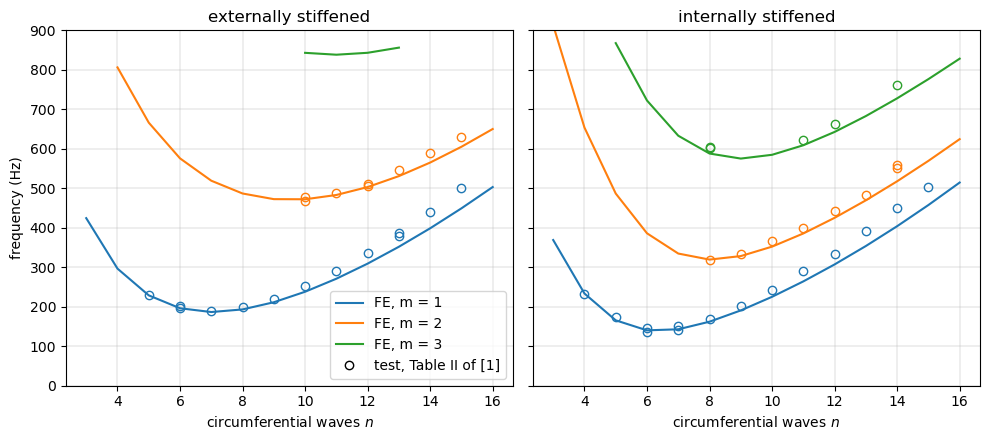

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
colors = {1: 'C0', 2: 'C1', 3: 'C2'}
for ax, side in zip(axes, ['external', 'internal']):
    model, f, mn, modes = results[side]
    fe = lowest_by_mn(f, mn)
    for m in [1, 2, 3]:
        ns = sorted(n for (mm, n) in fe if mm == m and 3 <= n <= 16)
        ax.plot(ns, [fe[(m, n)] for n in ns], '-', color=colors[m],
                label='FE, m = %d' % m)
        for (mm, n), ftest in test[side].items():
            if mm == m:
                ax.plot([n]*len(ftest), ftest, 'o', mfc='none',
                        color=colors[m])
    ax.plot([], [], 'ko', mfc='none', label='test, Table II of [1]')
    ax.set_title('%sly stiffened' % side)
    ax.set_xlabel('circumferential waves $n$')
    ax.set_ylim(0, 900)
    ax.grid(True, lw=0.3)
axes[0].set_ylabel('frequency (Hz)')
axes[0].legend(loc='lower right')
plt.tight_layout()
plt.show()

## Mode shapes

The normal displacement $w$ of the skin over the developed half cylinder
for three modes, with the stringers as thin lines, and, for the lowest
mode of each cylinder, the deformed cross-section at mid-length with the
stringers, the displacements greatly magnified:

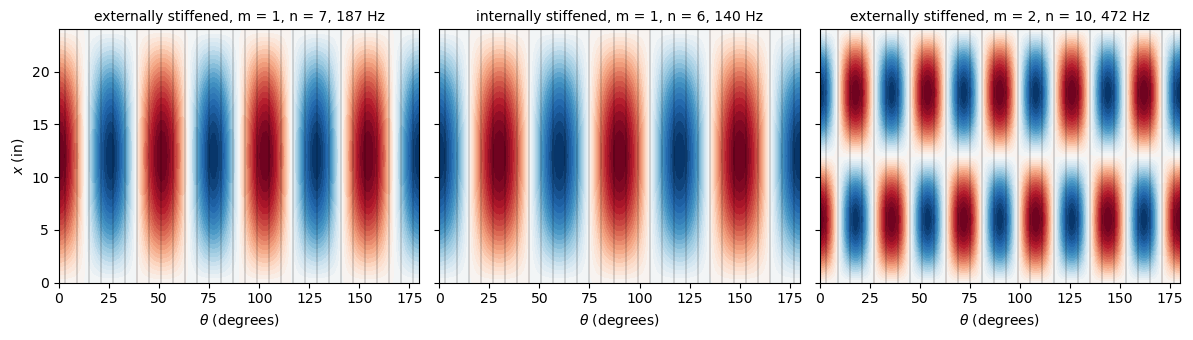

In [9]:
def plot_w(ax, model, mode, title):
    w = model.skin_field(mode, W)
    xx, tt = np.meshgrid(model.xlin, np.degrees(model.theta), indexing='ij')
    lim = np.abs(w).max()
    ax.contourf(tt, xx, w, levels=np.linspace(-lim, lim, 41), cmap='RdBu_r')
    for th in np.degrees(model.theta_stringer):
        ax.axvline(th, color='k', lw=0.2)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel(r'$\theta$ (degrees)')


fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for ax, (side, m, n) in zip(axes, [('external', 1, 7), ('internal', 1, 6),
                                   ('external', 2, 10)]):
    model, f, mn, modes = results[side]
    i = mn.index((m, n))
    plot_w(ax, model, modes[:, i],
           '%sly stiffened, m = %d, n = %d, %.0f Hz' % (side, m, n, f[i]))
axes[0].set_ylabel('$x$ (in)')
plt.tight_layout()
plt.show()

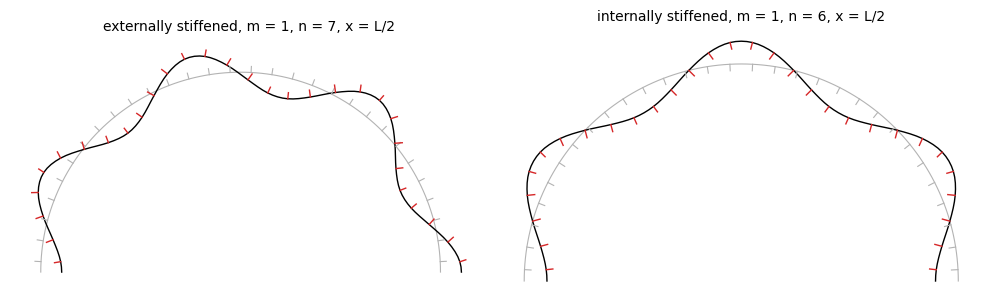

In [10]:
def plot_section(ax, model, mode, scale):
    i = model.nx//2
    R = model.R
    th = model.theta
    v = model.skin_field(mode, V)[i]
    w = model.skin_field(mode, W)[i]
    norm = scale/np.abs(w).max()
    ax.plot(R*np.cos(th), R*np.sin(th), color='0.7', lw=0.8)
    r = R + norm*w
    t = th + norm*v/R
    ax.plot(r*np.cos(t), r*np.sin(t), 'k', lw=1)
    for s, ths in enumerate(model.theta_stringer):
        nodes = model.str_nodes[s, i]
        r0 = R + model.Y
        ax.plot(r0*np.cos(ths), r0*np.sin(ths), color='0.7', lw=0.8)
        r = r0 + norm*mode[DOF*nodes + V]
        t = ths + norm*mode[DOF*nodes + W]/r0
        ax.plot(r*np.cos(t), r*np.sin(t), 'C3', lw=1)
    ax.set_aspect('equal')
    ax.axis('off')


fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, (side, m, n) in zip(axes, [('external', 1, 7), ('internal', 1, 6)]):
    model, f, mn, modes = results[side]
    i = mn.index((m, n))
    plot_section(ax, model, modes[:, i], scale=1.)
    ax.set_title('%sly stiffened, m = %d, n = %d, x = L/2' % (side, m, n),
                 fontsize=10)
plt.tight_layout()
plt.show()

## Discussion

The lowest measured frequencies are 189 Hz ($m = 1$, $n = 7$) for the
externally stiffened cylinder and 137 and 147 Hz ($m = 1$, $n = 6$) for the
internally stiffened one, which [1] summarizes as minimum frequencies about
34 % higher with external stringers. The model gives its lowest
frequencies at the same $(m, n)$, 186.6 Hz and 140.2 Hz, 33 % apart: the
effect of the eccentricity of the stringers comes out of the connection of
the plates of the stringers to the skin, without any eccentricity
parameter. Near the minima, for $n \le 7$ with $m = 1$, the model is within
2.1 % of the tests, except the internally stiffened cylinder at $n = 5$
(5 % lower), and within 1 % for the lowest $m = 2$ modes.

The model is lower than the tests by a difference that grows with $n$, to
about 10 % at $n = 14$ and 15 for $m = 1$, for both cylinders, and by 4 to
7 % for $m = 2$ and $m = 3$ at the largest $n$ tested. For large $n$ the
frequencies are governed by the bending of the skin around the
circumference [1]. In the model the skin has the thickness $h$ everywhere
and each stringer is connected to it along a line, whereas the roots of
the actual stringers, 0.100 in wide with fillets of radius 1/16 in,
stiffen the skin locally over about a quarter of each 1.00 in bay. [1]
accounted for it with a circumferential bending stiffness of the skin
increased by 19.7 % and 19.5 % for the external and internal stringers
($D_y/D$ = 1.197 and 1.195, its appendix A), which raised its calculated
frequencies at $n = 15$ by about 9 % for $m = 1$ (its figure 7(a)). The
model has neither this local stiffening nor the two welded longitudinal
seams, where the skin is thicker (figure 1 of [1]), nor the support rings
of the tests, which did not restrain the skin between the stringers on
the stiffened side. It is not adjusted to the tests.

## Reference

[1] Sewall, J. L., and Naumann, E. C., *An experimental and analytical
vibration study of thin cylindrical shells with and without longitudinal
stiffeners*, NASA TN D-4705, 1968,
[NTRS 19680024266](https://ntrs.nasa.gov/citations/19680024266).